[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch09-concepts_workbook.ipynb)

# A classifier, five predictions and two hidden words

The lecture's examples, typed into the cells: a [CLS] vector of four numbers
read by a new classifier layer, GPT-2's probabilities for the five
predictions of `The cat sat on the mat`, and T5's span corruption of the same
sentence. What probability does the classifier give, how many bits does the
sentence cost, and how long are T5's input and target?

In [1]:
#@title Setup: run this cell first
import math

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# The lecture's classifier layer, stylised: one row of four weights per class.
POS, NEG = [0.5, 0.0, 1.0, -1.0], [-0.5, 1.0, 0.0, 0.5]
SENTENCE = "the cat sat on the mat"
# GPT-2 small's probabilities of cat, sat, on, the and mat, each after the words before it
# (figures/data/atlas-gpt2.json, revision 607a30d), to four significant figures.
GPT2_PROBS = [0.0001015, 0.0007037, 0.2240, 0.4537, 0.004044]
plt.rcParams.update({"xtick.labelsize": 8, "ytick.labelsize": 8})


class Refused(Exception):  # a setting a cell refuses: Colab prints the one sentence, without the stack
    _render_traceback_ = lambda self: [str(self)]  # noqa: E731


def bars(title, labels, values, xlabel, colors, fmt="%.3f"):  # one chart of labelled horizontal bars
    fig, ax = plt.subplots(figsize=(6, 0.4 * len(values) + 1.2), layout="constrained")
    b = ax.barh(range(len(values)), values, tick_label=labels, color=colors)
    ax.bar_label(b, fmt=fmt, padding=2, fontsize=8)
    ax.set(title=title, xlabel=xlabel, xlim=(0, 1.3 * (max(values) or 1)), ylim=(len(values) - 0.5, -0.5))
    plt.show()


# Step 1: the [CLS] vector times each class's row gives a logit; a softmax gives the probabilities.
def classify(h):
    if not (isinstance(h, list) and len(h) == 4 and all(type(x) in (int, float) and -10 <= x <= 10 for x in h)):
        raise Refused(f"VECTOR is {h!r}: VECTOR takes a list of 4 numbers from -10 to 10.")
    logits = [sum(w * x for w, x in zip(row, h)) for row in (POS, NEG)]
    return logits, 1 / (1 + math.exp(logits[1] - logits[0]))


def show_class(h):
    (lp, ln), p = classify(h)
    print(f"logits: positive {lp:.2f}, negative {ln:.2f}; P(positive) = 1/(1 + e^-({lp:.2f} - ({ln:.2f}))) = {p:.3f}")
    bars("the classifier's probabilities", ["positive", "negative"], [p, 1 - p], "probability", ["C3", "C0"])


# Step 2: the causal loss in bits, -log2 p per prediction, and the perplexity 2 ** (bits per prediction).
def bits(probs):
    if not (isinstance(probs, list) and 1 <= len(probs) <= 20 and all(type(p) in (int, float) and 0 < p <= 1 for p in probs)):
        raise Refused(f"PROBS is {probs!r}: PROBS takes a list of 1 to 20 probabilities above 0 and up to 1.")
    return [-math.log2(p) for p in probs]


def show_bits(probs):
    b = bits(probs)
    print(f"bits: {', '.join(f'{x:.2f}' for x in b)}; causal loss {sum(b):.2f} bits, perplexity {2 ** (sum(b) / len(b)):.1f}")
    words = SENTENCE.split()[1:] if len(b) == 5 else [f"prediction {k + 1}" for k in range(len(b))]  # five: the sentence's
    bars("bits per prediction", words, b, "bits", ["C3" if x == max(b) else "C0" for x in b], "%.2f")


# Step 3: span corruption: each hidden span becomes one sentinel in the input, and the target
# writes each span after its sentinel and ends on one more.
def corrupt(hide):
    words, spans, start = SENTENCE.split(), [], 0
    if not (isinstance(hide, list) and 1 <= len(hide) <= 3 and all(isinstance(s, str) and s.split() for s in hide)):
        raise Refused(f"HIDE is {hide!r}: HIDE takes a list of 1 to 3 spans of the sentence, in order.")
    for s in hide:
        n = len(s.split())
        a = next((i for i in range(start, len(words) - n + 1) if words[i:i + n] == s.split()), None)
        if a is None:
            raise Refused(f"HIDE is {hide!r}: {s!r} is no span of {SENTENCE!r} at least one word after the span before it.")
        spans, start = spans + [(a, a + n)], a + n + 1  # T5 merges touching spans into one
    inp, tgt, last = [], [], 0
    for j, (a, b) in enumerate(spans):
        inp, tgt, last = inp + words[last:a] + ["<" + "XYZ"[j] + ">"], tgt + ["<" + "XYZ"[j] + ">"] + words[a:b], b
    return inp + words[last:], tgt + ["<" + "XYZW"[len(spans)] + ">"]


def show_spans(hide):
    inp, tgt = corrupt(hide)
    print(f"input:  {' '.join(inp)}  ({len(inp)} tokens)\ntarget: {' '.join(tgt)}  ({len(tgt)} tokens)")
    bars("span corruption of " + SENTENCE, ["text", "encoder input", "target"], [6, len(inp), len(tgt)], "tokens",
         ["C7", "C0", "C3"], "%d")


# Appendix: BERT's masking rule at T positions.
def masking(T):
    k = 15 / 100 * T  # 15 per cent selected, of them 80 per cent [MASK], 10 a random token and 10 the original word
    return {"selected": k, "show [MASK]": 80 / 100 * k, "a random token": 10 / 100 * k, "the original word": 10 / 100 * k,
            "no loss term": T - k}


display(Markdown(f"Classifier rows: positive {POS}, negative {NEG}. Sentence: `{SENTENCE}`, {len(SENTENCE.split())} words."))

Classifier rows: positive [0.5, 0.0, 1.0, -1.0], negative [-0.5, 1.0, 0.0, 0.5]. Sentence: `the cat sat on the mat`, 6 words.

## 1. The [CLS] classifier

A fine-tuned classifier multiplies the [CLS] vector by one row of weights per
class and turns the two logits into probabilities with a softmax. Run the cell
for the lecture's vector: what probability of positive does it give? Then set
`VECTOR` to `[0, 1, 0, 2]`.

logits: positive 2.50, negative -1.00; P(positive) = 1/(1 + e^-(2.50 - (-1.00))) = 0.971


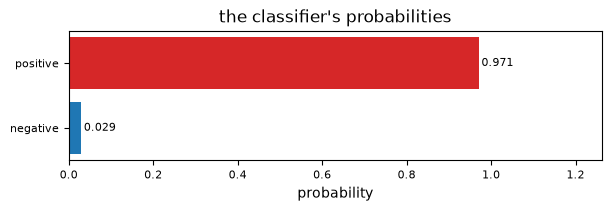

In [2]:
VECTOR = [1.0, -0.5, 2.0, 0.0]
show_class(VECTOR)

### Solution

In [3]:
(a, b), p = classify([1.0, -0.5, 2.0, 0.0])
(c, d), q = classify([0, 1, 0, 2])
display(Markdown(f"The lecture's vector gives logits {a:.1f} and {b:.1f} and a probability of positive of {p:.2f}; the vector "
                 f"`[0, 1, 0, 2]` gives {c:.1f} and {d:.1f}, so {q:.3f}. With two classes the softmax depends only on the "
                 "difference of the logits."))

The lecture's vector gives logits 2.5 and -1.0 and a probability of positive of 0.97; the vector `[0, 1, 0, 2]` gives -2.0 and 2.0, so 0.018. With two classes the softmax depends only on the difference of the logits.

## 2. Bits and perplexity

`PROBS` holds GPT-2's probabilities of the five words after `The`, each given
the words before it. A prediction of probability p costs minus log to base 2
of p bits, the causal loss is their sum, and the perplexity is 2 to the bits
per prediction. Run the cell: which word costs most? Then type the lecture's
question, `[0.5, 0.25, 0.125]`.

bits: 13.27, 10.47, 2.16, 1.14, 7.95; causal loss 34.99 bits, perplexity 127.8


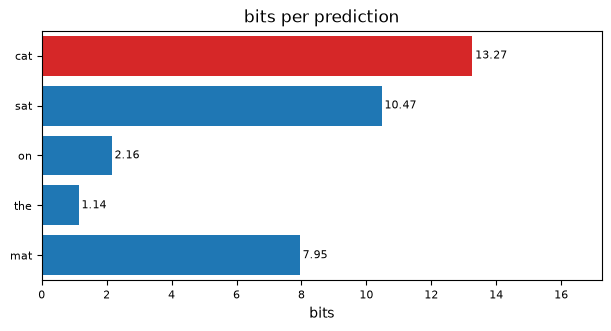

In [4]:
PROBS = GPT2_PROBS
show_bits(PROBS)

### Solution

In [5]:
g, h = bits(GPT2_PROBS), bits([0.5, 0.25, 0.125])
display(Markdown(f"GPT-2 spends {sum(g):.2f} bits on the five words, {g[0]:.2f} of them on `cat`, a perplexity of "
                 f"{2 ** (sum(g) / 5):.1f}. The question's probabilities cost {' + '.join(f'{x:.0f}' for x in h)} = {sum(h):.0f} "
                 f"bits, a perplexity of {2 ** (sum(h) / 3):.0f}."))

GPT-2 spends 34.99 bits on the five words, 13.27 of them on `cat`, a perplexity of 127.8. The question's probabilities cost 1 + 2 + 3 = 6 bits, a perplexity of 4.

## 3. Span corruption

`HIDE` lists the spans of the sentence T5 hides, in order. Each becomes one
sentinel token in the encoder input, `<X>` then `<Y>`, and the target writes
each span after its sentinel and ends on one more. Run the cell for the
lecture's span `sat on`: how long are the input and the target? Then hide
`cat` and `mat`.

input:  the cat <X> the mat  (5 tokens)
target: <X> sat on <Y>  (4 tokens)


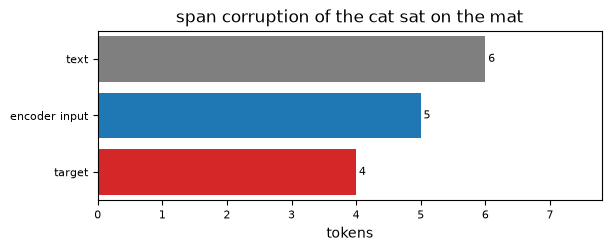

In [6]:
HIDE = ["sat on"]
show_spans(HIDE)

### Solution

In [7]:
(i1, t1), (i2, t2) = corrupt(["sat on"]), corrupt(["cat", "mat"])
display(Markdown(f"Hiding `sat on`: input `{' '.join(i1)}`, {len(i1)} tokens, and target `{' '.join(t1)}`, {len(t1)}. "
                 f"Hiding `cat` and `mat`: `{' '.join(i2)}`, {len(i2)} tokens, and `{' '.join(t2)}`, {len(t2)}: "
                 "each span becomes one sentinel in the input and one in the target, which ends on one more."))

Hiding `sat on`: input `the cat <X> the mat`, 5 tokens, and target `<X> sat on <Y>`, 4. Hiding `cat` and `mat`: `the <X> sat on the <Y>`, 6 tokens, and `<X> cat <Y> mat <Z>`, 5: each span becomes one sentinel in the input and one in the target, which ends on one more.

## Appendix. BERT's masking rule

BERT selects 15 per cent of the positions of a text for prediction, and each selected
position gives a loss term. Of those, 80 per cent show [MASK], 10 per cent a
random token and 10 per cent the original word. The chart splits 512
positions.

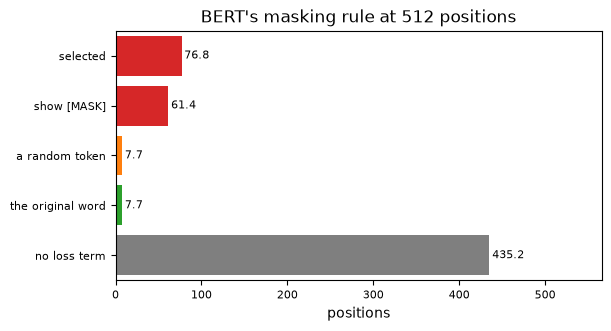

In [8]:
rule = masking(512)
bars("BERT's masking rule at 512 positions", list(rule), list(rule.values()), "positions", ["C3", "C3", "C1", "C2", "C7"], "%.1f")

**Exercise.** Set `POSITIONS` to 1000 and then to 200. How many positions are
selected, and how many of them show [MASK]? How many give no loss term?

In [9]:
POSITIONS = 512

if type(POSITIONS) is not int or not 1 <= POSITIONS <= 100000:
    raise Refused(f"POSITIONS is {POSITIONS!r}: POSITIONS takes a whole number from 1 to 100000.")
print("; ".join(f"{k} {v:,.1f}" for k, v in masking(POSITIONS).items()))

selected 76.8; show [MASK] 61.4; a random token 7.7; the original word 7.7; no loss term 435.2


### Solution

In [10]:
m, n = masking(1000), masking(200)
display(Markdown(f"At 1,000 positions {m['selected']:.0f} are selected, {m['show [MASK]']:.0f} show [MASK], "
                 f"{m['a random token']:.0f} a random token and {m['the original word']:.0f} the original word, and "
                 f"{m['no loss term']:.0f} give no loss term. At 200: {n['selected']:.0f}, {n['show [MASK]']:.0f}, "
                 f"{n['a random token']:.0f}, {n['the original word']:.0f} and {n['no loss term']:.0f}."))

At 1,000 positions 150 are selected, 120 show [MASK], 15 a random token and 15 the original word, and 850 give no loss term. At 200: 30, 24, 3, 3 and 170.